In [3]:
!pip install pandas numpy matplotlib

In [4]:
import os, re, sys, json, csv, gzip, string
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
trainer_state_data = []
file_path = "/content/drive/MyDrive/CAISI_phase2/qlora-finetuning/16bit-checkpoints/checkpoint-1330/trainer_state.json"
with open(file_path, 'r') as file:
  data = json.load(file)

df = pd.json_normalize(data, record_path=["log_history"])

In [6]:
df

,epoch,grad_norm,learning_rate,loss,num_tokens,step,eval_loss,eval_num_tokens,eval_runtime,eval_samples_per_second,eval_steps_per_second
0,0.003759,0.699183,0.0002,1.3589,2683.0,1,NaN,NaN,NaN,NaN,NaN
1,0.037594,0.288367,0.0002,1.1103,32257.0,10,NaN,NaN,NaN,NaN,NaN
2,0.075188,0.186679,0.0002,1.0331,64998.0,20,NaN,NaN,NaN,NaN,NaN
3,0.112782,0.269544,0.0002,1.0475,93232.0,30,NaN,NaN,NaN,NaN,NaN
4,0.150376,0.225489,0.0002,0.9750,124868.0,40,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...
134,4.887218,0.713901,0.0002,0.1526,4018139.0,1300,NaN,NaN,NaN,NaN,NaN
135,4.924812,0.599329,0.0002,0.1517,4050632.0,1310,NaN,NaN,NaN,NaN,NaN
136,4.962406,0.712321,0.0002,0.1501,4082654.0,1320,NaN,NaN,NaN,NaN,NaN
137,5.000000,0.832999,0.0002,0.1683,4110920.0,1330,NaN,NaN,NaN,NaN,NaN


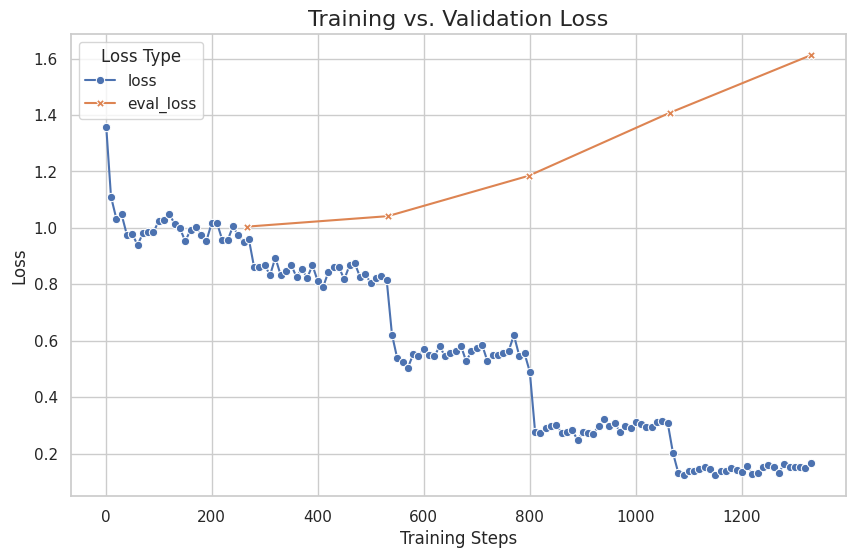

In [7]:
  log_history = pd.DataFrame(data.get("log_history", []))
  log_history = log_history[(log_history["loss"].notna()) | (log_history["eval_loss"].notna())]

  df_melted = log_history.melt(
      id_vars=["step"],
      value_vars=["loss", "eval_loss"],
      var_name="Loss Type",
      value_name="Loss"
  )

#Plot loss vs. steps

sns.set_theme(style="whitegrid")
plt.figure(figsize=(10,6))
sns.lineplot(
    data=df_melted,
    x="step", y="Loss", hue="Loss Type",
    style="Loss Type", markers=True, dashes=False
)
plt.xlabel("Training Steps", fontsize=12)
plt.ylabel("Loss", fontsize=12)
plt.title("Training vs. Validation Loss", fontsize=16)
plt.legend(title="Loss Type")
plt.show()